# Behavior Cloning and DAgger on MiniGrid

Portfolio packaging for Behrad Mazaheri. Original course/template credits below are retained; individual contributions are unverified.

**Static review only; no cells executed.** Historical outputs are preserved, not independently reproduced. Read README and REVIEW before citing results. Source cell indices in documentation are zero-based before this banner.

BFS expert has privileged symbolic environment access; the learner uses observations. A transition-level split can share trajectories between train and validation. Saved success: BC 50%, best selected DAgger 77.5%, best selected critical-state variant 65%. Selecting the best iteration on the same evaluation episodes is optimistic; use separate validation and final test seeds for a new experiment. Success is not monotonic across iterations or label budgets.


# Imitation Learning in MiniGrid DoorKey

This notebook builds a complete imitation-learning project around `MiniGrid-DoorKey-16x16-v0`. This larger DoorKey variant is still practical on CPU, but it gives behavior cloning much more room to drift into off-expert states.

We use three learners:

- behavior cloning (BC), trained only on expert demonstrations
- DAgger, which asks the expert to label states visited by the learner
- budgeted critical-state DAgger, which spends fewer expert labels on high-uncertainty learner states

All code lives in this notebook. Generated GIFs and plots are saved under `outputs/`.


In [1]:
# Lightweight dependency cell for Colab, Kaggle, and local notebooks.
# It only installs packages that are missing in the current kernel.
import importlib.util
import subprocess
import sys

required_packages = {
    "gymnasium": "gymnasium",
    "minigrid": "minigrid",
    "torch": "torch",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "imageio": "imageio",
    "tqdm": "tqdm",
}

missing = [pip_name for import_name, pip_name in required_packages.items()
           if importlib.util.find_spec(import_name) is None]

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")


Installing missing packages: ['minigrid']


## Project knobs

We use moderate defaults for the larger DoorKey map. The full run is still CPU-friendly, but the larger map and longer rollouts make the imitation-learning differences easier to see.


In [2]:
import copy
import math
import os
import random
from collections import deque
from dataclasses import dataclass
from pathlib import Path

import gymnasium as gym
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image as IPyImage
from IPython.display import Markdown, display
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

import minigrid  # Registers MiniGrid environments with Gymnasium.
from minigrid.wrappers import ViewSizeWrapper

# Experiment configuration. These defaults keep the full notebook practical on CPU.
ENV_ID = "MiniGrid-DoorKey-16x16-v0"
GRID_SIZE = 16
AGENT_VIEW_SIZE = 7
OUTPUT_DIR = Path("outputs/minigrid_imitation_learning")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
NUM_EXPERT_EPISODES = 80
MAX_STEPS_PER_EPISODE = 512

BATCH_SIZE = 128
BC_EPOCHS = 15
BC_LR = 1e-3
VAL_FRACTION = 0.15

EVAL_EPISODES = 40

DAGGER_ITERS = 4
DAGGER_ROLLOUTS_PER_ITER = 12
DAGGER_EPOCHS_PER_ITER = 6
DAGGER_LR = 5e-4

CRITICAL_ITERS = 4
CRITICAL_ROLLOUTS_PER_ITER = 12
CRITICAL_LABELS_PER_ITER = 150
CRITICAL_EPOCHS_PER_ITER = 6
CRITICAL_LR = 5e-4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


set_global_seed(SEED)
print(f"Using {DEVICE} for training; outputs will be saved to {OUTPUT_DIR.resolve()}")

c:\Users\psp\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using cuda for training; outputs will be saved to I:\دانشگاه\ترم 8\Deep RL\HW\HW_7\outputs\minigrid_imitation_learning


## 1. Loading, exploring, and visualizing the environment

We first load the environment and define small compatibility helpers. MiniGrid observations are dictionaries; the main observation used by the learner is the symbolic image tensor with shape `(7, 7, 3)`. The three channels encode object type, color, and object state.

The action space is discrete. The useful low-level actions here are left, right, forward, pickup, and toggle. Rewards are sparse: reaching the goal gives a positive reward, while most intermediate steps give zero. An episode terminates when the agent reaches the goal or when the time limit is reached.


In [3]:
# This is a helper function to create the MiniGrid environment. You may use it later. No need to change it.
def make_env(render_mode="rgb_array"):
    try:
        env = gym.make(ENV_ID, render_mode=render_mode)
    except TypeError:
        env = gym.make(ENV_ID)
    if AGENT_VIEW_SIZE != 7:
        env = ViewSizeWrapper(env, agent_view_size=AGENT_VIEW_SIZE)
    return env


# This is a helper function to reset Gymnasium or older Gym-style environments. You may use it later. No need to change it.
def reset_env(env, seed=None):
    if seed is None:
        result = env.reset()
    else:
        result = env.reset(seed=seed)
    if isinstance(result, tuple) and len(result) == 2:
        return result
    return result, {}


# This is a helper function to step Gymnasium or older Gym-style environments. You may use it later. No need to change it.
def step_env(env, action):
    result = env.step(int(action))
    if isinstance(result, tuple) and len(result) == 5:
        obs, reward, terminated, truncated, info = result
        done = bool(terminated or truncated)
        return obs, float(reward), done, info
    obs, reward, done, info = result
    return obs, float(reward), bool(done), info


# This is a helper function to read the MiniGrid image observation. You may use it later. No need to change it.
def obs_image(obs):
    if isinstance(obs, dict) and "image" in obs:
        return np.asarray(obs["image"], dtype=np.uint8)
    return np.asarray(obs, dtype=np.uint8)


# This is a helper function to render an RGB frame from the environment. You may use it later. No need to change it.
def render_env(env, tile_size=32):
    frame = None
    try:
        frame = env.render()
    except TypeError:
        frame = env.render(mode="rgb_array")
    if frame is None and hasattr(env.unwrapped, "get_frame"):
        frame = env.unwrapped.get_frame(tile_size=tile_size, agent_pov=False)
    return np.asarray(frame, dtype=np.uint8)


# This is a helper function to save frames as a GIF. You may use it later. No need to change it.
def save_gif(frames, path, fps=6):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    duration = 1.0 / fps
    imageio.mimsave(path, frames, duration=duration, loop=0)
    return path


# This is a helper function to display a generated GIF inline. You may use it later. No need to change it.
def display_gif(path):
    display(IPyImage(filename=str(path)))


# This is a helper function to read the agent position. You may use it later. No need to change it.
def get_agent_pos(env):
    pos = env.unwrapped.agent_pos
    return (int(pos[0]), int(pos[1]))


def rollout_policy(policy_fn, seed, gif_path=None, max_steps=MAX_STEPS_PER_EPISODE, fps=6):
    """Run one seeded episode and optionally save its rendered frames."""
    env = make_env(render_mode="rgb_array")
    frames, positions = [], []
    total_return = 0.0
    success = False

    try:
        obs, _ = reset_env(env, seed=int(seed))
        positions.append(get_agent_pos(env))
        if gif_path is not None:
            frames.append(render_env(env))

        steps = 0
        for steps in range(1, int(max_steps) + 1):
            action = int(policy_fn(obs, env))
            obs, reward, done, _ = step_env(env, action)
            total_return += reward
            success = success or reward > 0.0
            positions.append(get_agent_pos(env))
            if gif_path is not None:
                frames.append(render_env(env))
            if done:
                break

        saved_path = None
        if gif_path is not None and frames:
            saved_path = save_gif(frames, gif_path, fps=fps)

        return {
            "return": float(total_return),
            "success": bool(success),
            "length": int(steps),
            "positions": np.asarray(positions, dtype=np.int64),
            "gif_path": saved_path,
        }
    finally:
        env.close()


def evaluate_policy(policy_fn, n_episodes=EVAL_EPISODES, seed_start=0,
                    max_steps=MAX_STEPS_PER_EPISODE, record_positions=False):
    """Evaluate on deterministic seeds and aggregate returns, successes, and lengths."""
    rollouts = [
        rollout_policy(policy_fn, seed_start + episode, max_steps=max_steps)
        for episode in tqdm(range(int(n_episodes)), desc="evaluating", leave=False)
    ]
    returns = np.asarray([row["return"] for row in rollouts], dtype=np.float32)
    successes = np.asarray([row["success"] for row in rollouts], dtype=bool)
    lengths = np.asarray([row["length"] for row in rollouts], dtype=np.int64)
    if record_positions and rollouts:
        positions = np.concatenate([row["positions"] for row in rollouts], axis=0)
    else:
        positions = np.empty((0, 2), dtype=np.int64)

    return {
        "returns": returns,
        "successes": successes,
        "lengths": lengths,
        "success_rate": float(successes.mean()) if len(successes) else 0.0,
        "avg_return": float(returns.mean()) if len(returns) else 0.0,
        "avg_length": float(lengths.mean()) if len(lengths) else 0.0,
        "positions": positions,
    }


# This is a helper function to plot training curves. You may use it later. No need to change it.
def plot_training_curves(history, title="Training curves"):
    fig, ax1 = plt.subplots(figsize=(6, 3.5))
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    ax1.plot(epochs, history["train_loss"], label="train loss", color="tab:blue")
    if "val_loss" in history and len(history["val_loss"]) > 0:
        ax1.plot(epochs, history["val_loss"], label="val loss", color="tab:orange")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("cross-entropy loss")
    ax1.grid(alpha=0.25)

    if "val_acc" in history and len(history["val_acc"]) > 0:
        ax2 = ax1.twinx()
        ax2.plot(epochs, np.asarray(history["val_acc"]) * 100.0,
                 label="val accuracy", color="tab:green")
        ax2.set_ylabel("validation accuracy (%)")
        lines, labels = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines + lines2, labels + labels2, loc="center right")
    else:
        ax1.legend(loc="best")

    ax1.set_title(title)
    plt.tight_layout()
    plt.show()


# This is a helper function to plot a state visitation heatmap. You may use it later. No need to change it.
def plot_visit_heatmap(positions, width=GRID_SIZE, height=GRID_SIZE, ax=None, title="Visited states",
                       cmap="viridis", show_colorbar=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 4))
    counts = np.zeros((height, width), dtype=np.float32)
    for x, y in np.asarray(positions, dtype=np.int64):
        if 0 <= x < width and 0 <= y < height:
            counts[y, x] += 1.0

    im = ax.imshow(counts, origin="upper", cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_xticks(range(width))
    ax.set_yticks(range(height))
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.grid(which="major", color="white", linewidth=0.6, alpha=0.35)
    if show_colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return ax, counts

Environment: MiniGrid-DoorKey-16x16-v0
Observation keys: ['image', 'direction', 'mission']
Image observation shape: (7, 7, 3)
Action-space size: 7
Initial agent position/direction: (2, 10) 1


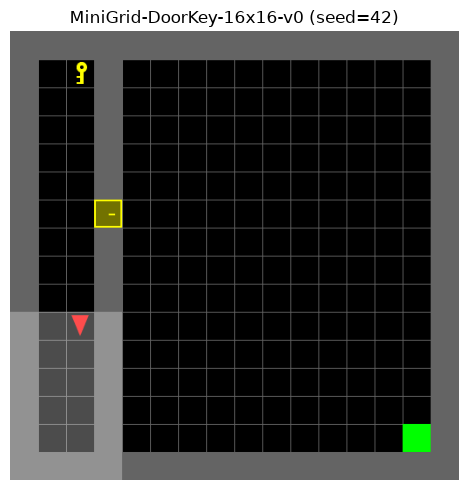

In [4]:
# Inspect one deterministic environment instance.
inspection_env = make_env(render_mode="rgb_array")
inspection_obs, _ = reset_env(inspection_env, seed=SEED)
inspection_frame = render_env(inspection_env)

print("Environment:", ENV_ID)
print("Observation keys:", list(inspection_obs) if isinstance(inspection_obs, dict) else "array")
print("Image observation shape:", obs_image(inspection_obs).shape)
print("Action-space size:", inspection_env.action_space.n)
print("Initial agent position/direction:", get_agent_pos(inspection_env), inspection_env.unwrapped.agent_dir)

assert obs_image(inspection_obs).shape == (AGENT_VIEW_SIZE, AGENT_VIEW_SIZE, 3)
assert inspection_env.unwrapped.width == GRID_SIZE

plt.figure(figsize=(5, 5))
plt.imshow(inspection_frame)
plt.title(f"{ENV_ID} (seed={SEED})")
plt.axis("off")
plt.tight_layout()
plt.show()
inspection_env.close()

{'return': 0.0, 'success': False, 'length': 100}


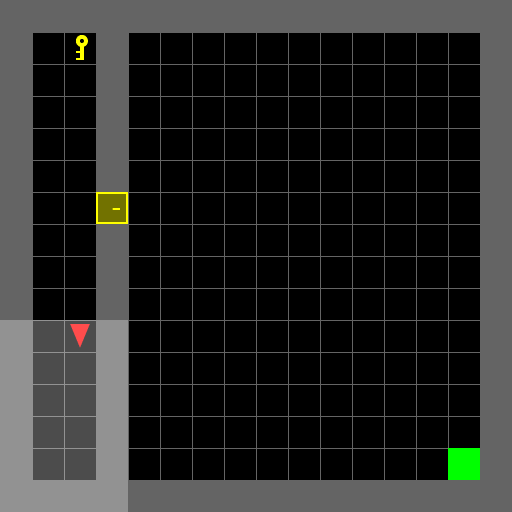

In [5]:
# A seeded random policy restricted to the low-level actions useful in DoorKey.
random_rng = np.random.default_rng(SEED)
random_policy = lambda obs, env: int(random_rng.choice([0, 1, 2, 3, 5]))
random_rollout = rollout_policy(
    random_policy,
    seed=SEED,
    gif_path=OUTPUT_DIR / "random_policy.gif",
    max_steps=100,
)
print({key: random_rollout[key] for key in ["return", "success", "length"]})
display_gif(random_rollout["gif_path"])

## 2. Generating expert demonstrations with a BFS oracle

We now build an expert planner from scratch. The oracle is allowed to use privileged full-state access to the grid layout. It plans over symbolic states:

- agent position `(x, y)`
- agent direction
- whether the key is currently carried
- whether the door is open or locked

The plan is still executed with valid low-level MiniGrid actions: turn left, turn right, move forward, pick up, and toggle the door.


In [8]:
LEFT, RIGHT, FORWARD, PICKUP, DROP, TOGGLE, DONE = range(7)
DIR_TO_VEC = {
    0: (1, 0),    # east
    1: (0, 1),    # south
    2: (-1, 0),   # west
    3: (0, -1),   # north
}
ORACLE_ACTIONS = [FORWARD, PICKUP, TOGGLE, LEFT, RIGHT]

@dataclass(frozen=True)
class DoorKeyLayout:
    width: int
    height: int
    walls: frozenset
    key_pos: tuple
    door_pos: tuple
    goal_pos: tuple


def build_layout(env):
    """Extract the static DoorKey layout using the oracle's privileged state access."""
    grid = env.unwrapped.grid
    walls = set()
    key_pos, door_pos, goal_pos = None, None, None

    for x in range(grid.width):
        for y in range(grid.height):
            cell = grid.get(x, y)
            if cell is None:
                continue
            cell_type = getattr(cell, "type", None)
            if cell_type == "wall":
                walls.add((x, y))
            elif cell_type == "key":
                key_pos = (x, y)
            elif cell_type == "door":
                door_pos = (x, y)
            elif cell_type == "goal":
                goal_pos = (x, y)

    if key_pos is None or door_pos is None or goal_pos is None:
        raise RuntimeError("DoorKey layout must contain exactly one key, door, and goal.")

    return DoorKeyLayout(
        width=int(grid.width),
        height=int(grid.height),
        walls=frozenset(walls),
        key_pos=key_pos,
        door_pos=door_pos,
        goal_pos=goal_pos,
    )


def symbolic_state_from_env(env, layout):
    """Encode all state variables needed by the deterministic BFS model."""
    x, y = get_agent_pos(env)
    direction = int(env.unwrapped.agent_dir)
    carrying = env.unwrapped.carrying
    has_key = carrying is not None and getattr(carrying, "type", None) == "key"

    door = env.unwrapped.grid.get(*layout.door_pos)
    if door is None or getattr(door, "type", None) != "door":
        raise RuntimeError("The stored door position no longer contains a door.")
    door_open = bool(door.is_open)
    door_locked = bool(door.is_locked)

    return (x, y, direction, has_key, door_open, door_locked)


# This is a helper function to compute the cell in front of a symbolic state. You may use it later. No need to change it.
def front_cell(state):
    x, y, direction, has_key, door_open, door_locked = state
    dx, dy = DIR_TO_VEC[int(direction)]
    return (x + dx, y + dy)


# This is a helper function to test whether a symbolic state can enter a grid cell. You may use it later. No need to change it.
def can_enter_cell(layout, pos, has_key, door_open):
    x, y = pos
    if x < 0 or x >= layout.width or y < 0 or y >= layout.height:
        return False
    if pos in layout.walls:
        return False
    if pos == layout.door_pos:
        return bool(door_open)
    if pos == layout.key_pos and not has_key:
        return False
    return True


def symbolic_transition(layout, state, action):
    """Apply one valid MiniGrid low-level action to a symbolic state."""
    x, y, direction, has_key, door_open, door_locked = state
    action = int(action)

    if action == LEFT:
        direction = (direction - 1) % 4
    elif action == RIGHT:
        direction = (direction + 1) % 4
    elif action == FORWARD:
        next_pos = front_cell(state)
        if can_enter_cell(layout, next_pos, has_key, door_open):
            x, y = next_pos
    elif action == PICKUP:
        if not has_key and front_cell(state) == layout.key_pos:
            has_key = True
    elif action == TOGGLE:
        if front_cell(state) == layout.door_pos:
            if door_locked and has_key:
                door_locked = False
                door_open = True
            elif not door_locked:
                door_open = not door_open

    return (int(x), int(y), int(direction), bool(has_key), bool(door_open), bool(door_locked))


# This is a helper function to recover an action sequence from BFS parent pointers. You may use it later. No need to change it.
def reconstruct_plan(parent, action_taken, goal_state):
    actions = []
    state = goal_state
    while parent[state] is not None:
        actions.append(action_taken[state])
        state = parent[state]
    actions.reverse()
    return actions


def oracle_plan_from_state(layout, start_state):
    """Return a shortest action sequence to the goal using breadth-first search."""
    if tuple(start_state[:2]) == layout.goal_pos:
        return []

    frontier = deque([start_state])
    parent = {start_state: None}
    action_taken = {}

    while frontier:
        state = frontier.popleft()
        for action in ORACLE_ACTIONS:
            next_state = symbolic_transition(layout, state, action)
            if next_state == state or next_state in parent:
                continue
            parent[next_state] = state
            action_taken[next_state] = int(action)
            if tuple(next_state[:2]) == layout.goal_pos:
                return reconstruct_plan(parent, action_taken, next_state)
            frontier.append(next_state)

    raise RuntimeError(f"No plan found from symbolic state {start_state}.")


# This is a helper function to query the expert action for the current environment state. You may use it later. No need to change it.
def oracle_action_from_env(env, layout):
    state = symbolic_state_from_env(env, layout)
    plan = oracle_plan_from_state(layout, state)
    if not plan:
        return DONE
    return int(plan[0])


# This is a helper function to query the expert action for a stored symbolic state. You may use it later. No need to change it.
def oracle_action_from_symbolic_state(layout, state):
    plan = oracle_plan_from_state(layout, state)
    if not plan:
        return DONE
    return int(plan[0])

def make_oracle_policy():
    """Create an oracle callable with a safe per-environment layout cache."""
    cached_env = None
    cached_layout = None

    def policy(obs, env):
        nonlocal cached_env, cached_layout
        base_env = env.unwrapped

        if base_env is not cached_env or int(base_env.step_count) == 0:
            cached_env = base_env
            cached_layout = build_layout(env)

        return oracle_action_from_env(env, cached_layout)

    return policy

In [9]:
# Verify the symbolic transition model by executing the oracle in real environments.
oracle_eval = evaluate_policy(
    make_oracle_policy(),
    n_episodes=20,
    seed_start=100,
    record_positions=True,
)
print(f"Oracle success rate: {oracle_eval['success_rate'] * 100:.1f}%")
print(f"Oracle average length: {oracle_eval['avg_length']:.1f}")
assert oracle_eval["success_rate"] == 1.0, "The BFS oracle should solve every tested seed."

Oracle success rate: 100.0%
Oracle average length: 35.6


expert demonstrations: 100%|██████████| 80/80 [00:07<00:00, 11.09it/s]


Expert transitions: 2639
Expert episodes: 80
Expert success rate: 1.0
Expert average length: 32.99


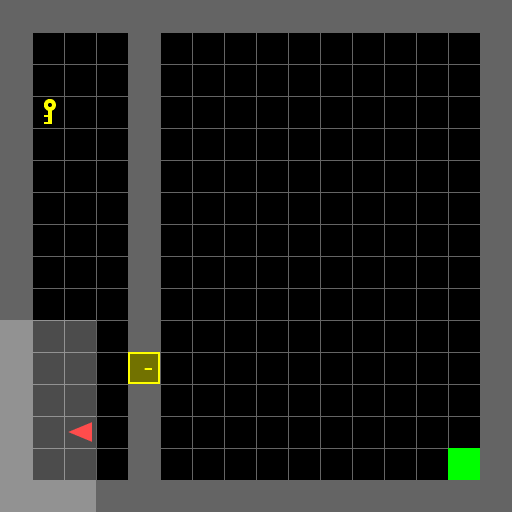

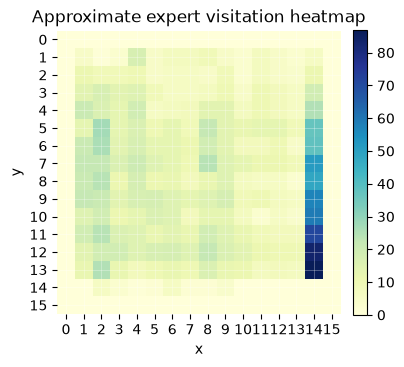

In [10]:
def generate_expert_dataset(n_episodes, seed_start=1000, max_steps=MAX_STEPS_PER_EPISODE):
    """Generate observation/action demonstrations and episode-level diagnostics."""
    images, actions, positions, symbolic_states, episode_ids = [], [], [], [], []
    episode_returns, episode_lengths, episode_successes = [], [], []

    for episode in tqdm(range(int(n_episodes)), desc="expert demonstrations"):
        env = make_env(render_mode="rgb_array")
        try:
            obs, _ = reset_env(env, seed=seed_start + episode)
            layout = build_layout(env)
            total_return = 0.0
            success = False
            steps = 0

            for steps in range(1, int(max_steps) + 1):
                state = symbolic_state_from_env(env, layout)
                expert_action = oracle_action_from_symbolic_state(layout, state)
                if expert_action == DONE:
                    break

                images.append(obs_image(obs).copy())
                actions.append(expert_action)
                positions.append(get_agent_pos(env))
                symbolic_states.append(state)
                episode_ids.append(episode)

                obs, reward, done, _ = step_env(env, expert_action)
                total_return += reward
                success = success or reward > 0.0
                if done:
                    break

            episode_returns.append(total_return)
            episode_lengths.append(steps)
            episode_successes.append(success)
        finally:
            env.close()

    return {
        "obs": np.asarray(images, dtype=np.uint8),
        "actions": np.asarray(actions, dtype=np.int64),
        "positions": np.asarray(positions, dtype=np.int64),
        "symbolic_states": symbolic_states,
        "episode_ids": np.asarray(episode_ids, dtype=np.int64),
        "episode_returns": np.asarray(episode_returns, dtype=np.float32),
        "episode_lengths": np.asarray(episode_lengths, dtype=np.int64),
        "episode_successes": np.asarray(episode_successes, dtype=bool),
    }


expert_data = generate_expert_dataset(NUM_EXPERT_EPISODES)

print("Expert transitions:", len(expert_data["actions"]))
print("Expert episodes:", NUM_EXPERT_EPISODES)
print("Expert success rate:", expert_data["episode_successes"].mean())
print("Expert average length:", expert_data["episode_lengths"].mean().round(2))

assert expert_data["episode_successes"].all(), "Every expert demonstration should succeed."
expert_gif = rollout_policy(
    make_oracle_policy(),
    seed=1000,
    gif_path=OUTPUT_DIR / "expert_policy.gif",
)
display_gif(expert_gif["gif_path"])

plot_visit_heatmap(
    expert_data["positions"],
    title="Approximate expert visitation heatmap",
    cmap="YlGnBu",
)
plt.show()

## 3. Training a behavior cloning policy

Behavior cloning turns imitation learning into supervised learning. We train a policy to predict the expert action from the MiniGrid image observation.

$$
L_{BC}(\theta) = -\mathbb{E}_{(s,a)\sim D_E}\log \pi_\theta(a\mid s).
$$

We use a deliberately small CNN. The observation is symbolic rather than photographic, so a compact model is enough for this project.


In [11]:
# MiniGrid encodes object, color, and state with maxima 10, 5, and 2.
OBS_NORMALIZER = torch.tensor([10.0, 5.0, 2.0], dtype=torch.float32).view(3, 1, 1)
N_ACTIONS = 7


# This is a helper function to preprocess one MiniGrid image for the model. You may use it later. No need to change it.
def preprocess_image(image):
    x = torch.as_tensor(image, dtype=torch.float32)
    if x.ndim != 3:
        raise ValueError(f"Expected image with 3 dimensions, got shape {tuple(x.shape)}")
    if x.shape[-1] == 3:
        x = x.permute(2, 0, 1)
    return x / OBS_NORMALIZER


# This is a helper function to turn an observation into a model input batch. You may use it later. No need to change it.
def obs_to_tensor(obs, device=DEVICE):
    x = preprocess_image(obs_image(obs)).unsqueeze(0)
    return x.to(device)


class ImageActionDataset(Dataset):
    def __init__(self, images, actions, indices=None):
        self.images = np.asarray(images, dtype=np.uint8)
        self.actions = np.asarray(actions, dtype=np.int64)
        if len(self.images) != len(self.actions):
            raise ValueError("images and actions must have the same length")
        self.indices = (np.arange(len(self.actions), dtype=np.int64) if indices is None
                        else np.asarray(indices, dtype=np.int64))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        source_index = int(self.indices[index])
        return preprocess_image(self.images[source_index]), int(self.actions[source_index])


def make_data_loaders(images, actions, val_fraction=VAL_FRACTION,
                      batch_size=BATCH_SIZE, seed=SEED):
    """Split indices reproducibly, keeping validation examples out of training."""
    n_examples = len(actions)
    if n_examples < 2:
        raise ValueError("At least two examples are required for a train/validation split.")

    generator = torch.Generator().manual_seed(int(seed))
    indices = torch.randperm(n_examples, generator=generator).numpy()
    n_val = max(1, int(round(float(val_fraction) * n_examples)))
    n_val = min(n_val, n_examples - 1)
    val_indices, train_indices = indices[:n_val], indices[n_val:]

    train_dataset = ImageActionDataset(images, actions, train_indices)
    val_dataset = ImageActionDataset(images, actions, val_indices)
    loader_kwargs = {
        "batch_size": int(batch_size),
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
    }
    train_loader = DataLoader(train_dataset, shuffle=True, generator=generator, **loader_kwargs)
    val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
    return train_loader, val_loader


class SmallMinigridPolicy(nn.Module):
    def __init__(self, n_actions=N_ACTIONS):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Flatten(),
        )
        self.policy_head = nn.Sequential(
            nn.Linear(64 * AGENT_VIEW_SIZE * AGENT_VIEW_SIZE, 256),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(256, int(n_actions)),
        )

    def forward(self, x):
        return self.policy_head(self.features(x))


def mask_invalid_logits(logits):
    """Exclude DROP and DONE while preserving native MiniGrid action indices."""
    valid = torch.zeros(logits.shape[-1], dtype=torch.bool, device=logits.device)
    valid[torch.as_tensor(ORACLE_ACTIONS, device=logits.device)] = True
    return logits.masked_fill(~valid, -1e9)


def train_policy(model, train_loader, val_loader=None, epochs=5, lr=1e-3,
                 device=DEVICE, desc="training"):
    """Train with cross-entropy and restore the checkpoint with minimum validation loss."""
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=float(lr))
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_state = copy.deepcopy(model.state_dict())
    best_score = float("inf")

    for _ in tqdm(range(int(epochs)), desc=desc, leave=False):
        model.train()
        train_loss_sum, train_count = 0.0, 0
        for images, actions in train_loader:
            images = images.to(device, non_blocking=True)
            actions = actions.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = mask_invalid_logits(model(images))
            loss = F.cross_entropy(logits, actions)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            train_loss_sum += loss.item() * len(actions)
            train_count += len(actions)

        train_loss = train_loss_sum / max(train_count, 1)
        history["train_loss"].append(train_loss)

        if val_loader is not None:
            model.eval()
            val_loss_sum, val_correct, val_count = 0.0, 0, 0
            with torch.no_grad():
                for images, actions in val_loader:
                    images = images.to(device, non_blocking=True)
                    actions = actions.to(device, non_blocking=True)
                    logits = mask_invalid_logits(model(images))
                    loss = F.cross_entropy(logits, actions)
                    val_loss_sum += loss.item() * len(actions)
                    val_correct += (logits.argmax(dim=-1) == actions).sum().item()
                    val_count += len(actions)
            val_loss = val_loss_sum / max(val_count, 1)
            val_acc = val_correct / max(val_count, 1)
        else:
            val_loss, val_acc = train_loss, float("nan")

        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if val_loss < best_score:
            best_score = val_loss
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return history


@torch.no_grad()
def model_action(model, obs, deterministic=True, temperature=1.0):
    """Return a native MiniGrid action, masking actions unused by the oracle."""
    if temperature <= 0:
        raise ValueError("temperature must be positive")
    model.eval()
    logits = mask_invalid_logits(model(obs_to_tensor(obs))) / float(temperature)
    if deterministic:
        return int(logits.argmax(dim=-1).item())
    return int(torch.distributions.Categorical(logits=logits).sample().item())


@torch.no_grad()
def model_entropy(model, obs):
    """Compute categorical entropy over the five allowed DoorKey actions."""
    model.eval()
    logits = model(obs_to_tensor(obs))
    allowed_logits = logits[:, ORACLE_ACTIONS]
    probabilities = F.softmax(allowed_logits, dim=-1)
    entropy = -(probabilities * probabilities.clamp_min(1e-12).log()).sum(dim=-1)
    return float(entropy.item())

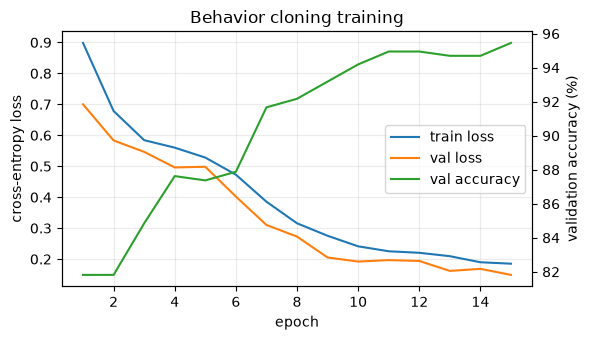

Final validation accuracy: 95.5%
BC success rate: 50.0%
BC average return: 0.491
BC average episode length: 280.8


In [12]:
train_loader, val_loader = make_data_loaders(
    expert_data["obs"],
    expert_data["actions"],
    seed=SEED,
)

bc_model = SmallMinigridPolicy().to(DEVICE)
bc_history = train_policy(
    bc_model,
    train_loader,
    val_loader,
    epochs=BC_EPOCHS,
    lr=BC_LR,
    desc="BC",
)

plot_training_curves(bc_history, title="Behavior cloning training")

bc_eval = evaluate_policy(
    lambda obs, env: model_action(bc_model, obs, deterministic=True),
    n_episodes=EVAL_EPISODES,
    seed_start=3000,
    record_positions=True,
)

print(f"Final validation accuracy: {bc_history['val_acc'][-1] * 100:.1f}%")
print(f"BC success rate: {bc_eval['success_rate'] * 100:.1f}%")
print(f"BC average return: {bc_eval['avg_return']:.3f}")
print(f"BC average episode length: {bc_eval['avg_length']:.1f}")

## 4. Rolling out BC and showing where it fails

The learner now acts in the real environment. We search over seeds for a BC failure case and display the first failure found.

The main failure mode is distribution mismatch: small supervised errors can move the learner into states that were rare or absent in the expert demonstrations. Once there, the policy has less useful training signal.


BC failure found automatically at seed 4000.
{'return': 0.0, 'success': False, 'length': 512}


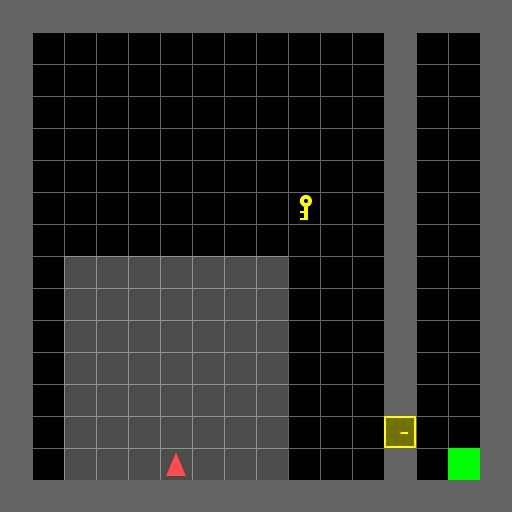

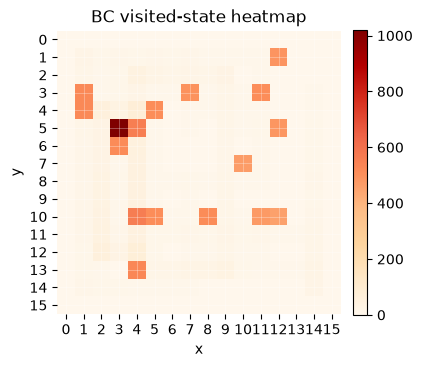

In [13]:
def find_seed_for_outcome(policy_fn, target_success, seed_start=4000, n_search=100):
    """Return the first seed whose rollout success matches the requested outcome."""
    for seed in range(int(seed_start), int(seed_start) + int(n_search)):
        result = rollout_policy(policy_fn, seed=seed)
        if result["success"] == bool(target_success):
            return seed
    return None


bc_policy_fn = lambda obs, env: model_action(bc_model, obs, deterministic=True)
bc_failure_seed = find_seed_for_outcome(
    bc_policy_fn,
    target_success=False,
    seed_start=4000,
    n_search=200,
)

assert bc_failure_seed is not None, "Expected to find a BC failure seed. Increase n_search or use a larger DoorKey variant."
print(f"BC failure found automatically at seed {bc_failure_seed}.")

bc_rollout = rollout_policy(
    bc_policy_fn,
    seed=bc_failure_seed,
    gif_path=OUTPUT_DIR / "bc_failure.gif",
)
print({
    "return": round(bc_rollout["return"], 3),
    "success": bc_rollout["success"],
    "length": bc_rollout["length"],
})
display_gif(bc_rollout["gif_path"])

plot_visit_heatmap(
    bc_eval["positions"],
    title="BC visited-state heatmap",
    cmap="OrRd",
)
plt.show()

## 5. Implementing DAgger

DAgger fixes the dataset mismatch by asking the expert to label states visited by the learner:

$$
D \leftarrow D \cup \{(s, \pi_E(s)) : s \text{ visited by } \pi_\theta\}.
$$

Then we continue training the policy on the aggregated dataset. We track both success rate and the number of expert labels used.


DAgger 1: labels=4737, success=70.0%


DAgger 2: labels=6827, success=77.5%


DAgger 3: labels=9311, success=30.0%


DAgger 4: labels=11957, success=55.0%


Best DAgger success rate: 77.5%


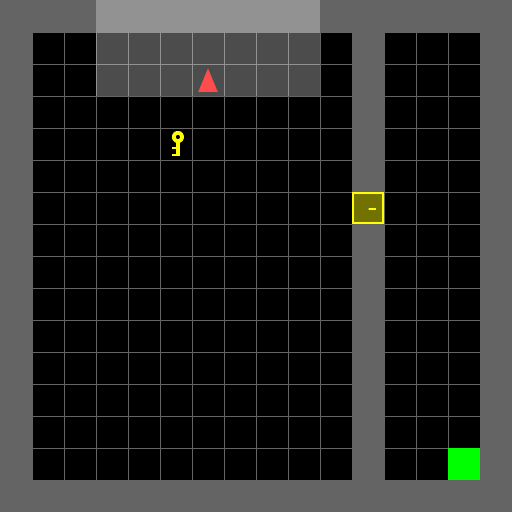

In [14]:
def collect_dagger_labels(model, n_rollouts, seed_start, max_steps=MAX_STEPS_PER_EPISODE,
                          stochastic_rollout=False):
    """Label every state visited by the learner with the BFS oracle action."""
    images, actions, positions = [], [], []
    episode_lengths, episode_successes = [], []

    for episode in tqdm(range(int(n_rollouts)), desc="DAgger rollouts", leave=False):
        env = make_env(render_mode="rgb_array")
        try:
            obs, _ = reset_env(env, seed=seed_start + episode)
            layout = build_layout(env)
            success = False
            steps = 0

            for steps in range(1, int(max_steps) + 1):
                expert_action = oracle_action_from_env(env, layout)
                if expert_action == DONE:
                    break
                images.append(obs_image(obs).copy())
                actions.append(expert_action)
                positions.append(get_agent_pos(env))

                learner_action = model_action(
                    model, obs, deterministic=not stochastic_rollout, temperature=1.0
                )
                obs, reward, done, _ = step_env(env, learner_action)
                success = success or reward > 0.0
                if done:
                    break

            episode_lengths.append(steps)
            episode_successes.append(success)
        finally:
            env.close()

    return {
        "obs": np.asarray(images, dtype=np.uint8),
        "actions": np.asarray(actions, dtype=np.int64),
        "positions": np.asarray(positions, dtype=np.int64),
        "episode_lengths": np.asarray(episode_lengths, dtype=np.int64),
        "episode_successes": np.asarray(episode_successes, dtype=bool),
    }


# Start from BC, aggregate learner-state labels, and keep the strongest iteration.
dagger_model = copy.deepcopy(bc_model).to(DEVICE)
dagger_images = [image.copy() for image in expert_data["obs"]]
dagger_actions = expert_data["actions"].astype(np.int64).tolist()
initial_dagger_eval = evaluate_policy(
    lambda obs, env: model_action(dagger_model, obs),
    n_episodes=EVAL_EPISODES,
    seed_start=6000,
)
dagger_history = [{"iteration": 0, "labels": len(dagger_actions), **initial_dagger_eval}]
dagger_train_histories = []
best_dagger_model = copy.deepcopy(dagger_model)
best_dagger_score = (initial_dagger_eval["success_rate"], initial_dagger_eval["avg_return"])

for iteration in range(1, DAGGER_ITERS + 1):
    new_labels = collect_dagger_labels(
        dagger_model,
        n_rollouts=DAGGER_ROLLOUTS_PER_ITER,
        seed_start=5000 + 100 * iteration,
        stochastic_rollout=True,
    )
    dagger_images.extend(new_labels["obs"])
    dagger_actions.extend(new_labels["actions"].tolist())

    train_loader, val_loader = make_data_loaders(
        np.asarray(dagger_images, dtype=np.uint8),
        np.asarray(dagger_actions, dtype=np.int64),
        seed=SEED + iteration,
    )
    iteration_history = train_policy(
        dagger_model,
        train_loader,
        val_loader,
        epochs=DAGGER_EPOCHS_PER_ITER,
        lr=DAGGER_LR,
        desc=f"DAgger {iteration}/{DAGGER_ITERS}",
    )
    dagger_train_histories.append(iteration_history)

    iteration_eval = evaluate_policy(
        lambda obs, env: model_action(dagger_model, obs),
        n_episodes=EVAL_EPISODES,
        seed_start=6000,
    )
    dagger_history.append({"iteration": iteration, "labels": len(dagger_actions), **iteration_eval})
    score = (iteration_eval["success_rate"], iteration_eval["avg_return"])
    print(f"DAgger {iteration}: labels={len(dagger_actions)}, success={score[0] * 100:.1f}%")
    if score > best_dagger_score:
        best_dagger_score = score
        best_dagger_model = copy.deepcopy(dagger_model)

dagger_model = best_dagger_model.to(DEVICE)
dagger_label_count = len(dagger_actions)
dagger_eval = evaluate_policy(
    lambda obs, env: model_action(dagger_model, obs),
    n_episodes=EVAL_EPISODES,
    seed_start=6000,
    record_positions=True,
)
dagger_gif = rollout_policy(
    lambda obs, env: model_action(dagger_model, obs),
    seed=6000,
    gif_path=OUTPUT_DIR / "dagger_best.gif",
)
print(f"Best DAgger success rate: {dagger_eval['success_rate'] * 100:.1f}%")
display_gif(dagger_gif["gif_path"])

## 6. Budgeted critical-state DAgger

Full DAgger can spend many labels. Here we roll out the learner, score visited states by policy entropy, and query the expert only on the top-k most uncertain states:

$$
H(\pi(\cdot\mid s)) = -\sum_a \pi(a\mid s)\log \pi(a\mid s).
$$

This is a simple active-learning version of DAgger: label the states where the policy is least sure.


In [15]:
def collect_uncertain_candidates(model, n_rollouts, seed_start, max_steps=MAX_STEPS_PER_EPISODE,
                                 stochastic_rollout=False):
    """Collect learner-visited states and score each with policy entropy."""
    candidates = []
    for episode in tqdm(range(int(n_rollouts)), desc="critical-state rollouts", leave=False):
        env = make_env(render_mode="rgb_array")
        try:
            obs, _ = reset_env(env, seed=seed_start + episode)
            layout = build_layout(env)
            for step in range(int(max_steps)):
                state = symbolic_state_from_env(env, layout)
                candidates.append({
                    "obs": obs_image(obs).copy(),
                    "entropy": model_entropy(model, obs),
                    "layout": layout,
                    "state": state,
                    "position": get_agent_pos(env),
                    "seed": seed_start + episode,
                    "step": step,
                })
                learner_action = model_action(
                    model, obs, deterministic=not stochastic_rollout, temperature=1.0
                )
                obs, _, done, _ = step_env(env, learner_action)
                if done:
                    break
        finally:
            env.close()
    return candidates


def label_top_uncertain_states(candidates, k):
    """Deduplicate symbolic states, then query the oracle for the top-k entropies."""
    selected, seen = [], set()
    ranked = sorted(candidates, key=lambda row: row["entropy"], reverse=True)
    for candidate in ranked:
        layout = candidate["layout"]
        identity = (
            layout.walls, layout.key_pos, layout.door_pos, layout.goal_pos,
            tuple(candidate["state"]),
        )
        if identity in seen:
            continue
        seen.add(identity)
        expert_action = oracle_action_from_symbolic_state(layout, candidate["state"])
        if expert_action == DONE:
            continue
        selected.append({**candidate, "action": expert_action})
        if len(selected) >= int(k):
            break

    return {
        "obs": np.asarray([row["obs"] for row in selected], dtype=np.uint8),
        "actions": np.asarray([row["action"] for row in selected], dtype=np.int64),
        "entropies": np.asarray([row["entropy"] for row in selected], dtype=np.float32),
        "positions": np.asarray([row["position"] for row in selected], dtype=np.int64),
    }


# Run entropy-budgeted DAgger from the same BC initialization.
critical_model = copy.deepcopy(bc_model).to(DEVICE)
critical_images = [image.copy() for image in expert_data["obs"]]
critical_actions = expert_data["actions"].astype(np.int64).tolist()
initial_critical_eval = evaluate_policy(
    lambda obs, env: model_action(critical_model, obs),
    n_episodes=EVAL_EPISODES,
    seed_start=6000,
)
critical_history = [{"iteration": 0, "labels": len(critical_actions), **initial_critical_eval}]
critical_train_histories = []
best_critical_model = copy.deepcopy(critical_model)
best_critical_score = (initial_critical_eval["success_rate"], initial_critical_eval["avg_return"])

for iteration in range(1, CRITICAL_ITERS + 1):
    candidates = collect_uncertain_candidates(
        critical_model,
        n_rollouts=CRITICAL_ROLLOUTS_PER_ITER,
        seed_start=7000 + 100 * iteration,
        stochastic_rollout=True,
    )
    new_labels = label_top_uncertain_states(candidates, CRITICAL_LABELS_PER_ITER)
    if len(new_labels["actions"]) == 0:
        print("No new unique critical states were available; stopping early.")
        break
    critical_images.extend(new_labels["obs"])
    critical_actions.extend(new_labels["actions"].tolist())

    train_loader, val_loader = make_data_loaders(
        np.asarray(critical_images, dtype=np.uint8),
        np.asarray(critical_actions, dtype=np.int64),
        seed=SEED + 100 + iteration,
    )
    iteration_history = train_policy(
        critical_model,
        train_loader,
        val_loader,
        epochs=CRITICAL_EPOCHS_PER_ITER,
        lr=CRITICAL_LR,
        desc=f"Critical DAgger {iteration}/{CRITICAL_ITERS}",
    )
    critical_train_histories.append(iteration_history)

    iteration_eval = evaluate_policy(
        lambda obs, env: model_action(critical_model, obs),
        n_episodes=EVAL_EPISODES,
        seed_start=6000,
    )
    critical_history.append({"iteration": iteration, "labels": len(critical_actions), **iteration_eval})
    score = (iteration_eval["success_rate"], iteration_eval["avg_return"])
    print(
        f"Critical DAgger {iteration}: labels={len(critical_actions)}, "
        f"mean queried entropy={new_labels['entropies'].mean():.3f}, success={score[0] * 100:.1f}%"
    )
    if score > best_critical_score:
        best_critical_score = score
        best_critical_model = copy.deepcopy(critical_model)

critical_model = best_critical_model.to(DEVICE)
critical_label_count = len(critical_actions)
critical_eval = evaluate_policy(
    lambda obs, env: model_action(critical_model, obs),
    n_episodes=EVAL_EPISODES,
    seed_start=6000,
    record_positions=True,
)
print(f"Best critical-state DAgger success rate: {critical_eval['success_rate'] * 100:.1f}%")

Critical DAgger 1: labels=2789, mean queried entropy=0.841, success=52.5%


Critical DAgger 2: labels=2939, mean queried entropy=0.746, success=62.5%


Critical DAgger 3: labels=3089, mean queried entropy=0.763, success=65.0%


Critical DAgger 4: labels=3239, mean queried entropy=0.763, success=55.0%


Best critical-state DAgger success rate: 65.0%


## 7. Final comparison and visual summary

We finish with label efficiency, final heatmaps, and a compact metrics table. The curves use expert-label count on the x-axis, so BC starts with the demonstration dataset and DAgger methods move right as they request more labels.


| method | expert labels used | success rate | average return | average episode length |
|---|---:|---:|---:|---:|
| Behavior cloning | 2639 | 40.0% | 0.394 | 325.3 |
| DAgger | 11957 | 67.5% | 0.663 | 200.1 |
| Critical-state DAgger | 3239 | 50.0% | 0.492 | 279.0 |

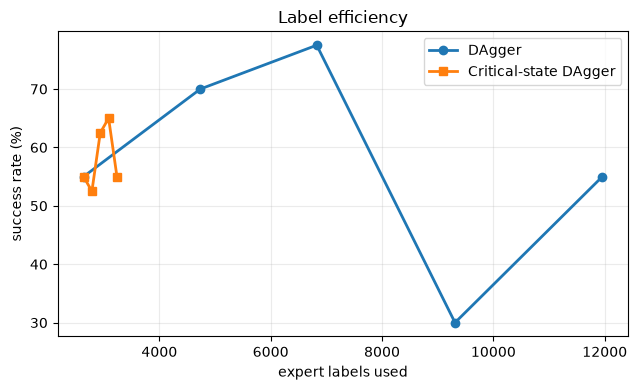

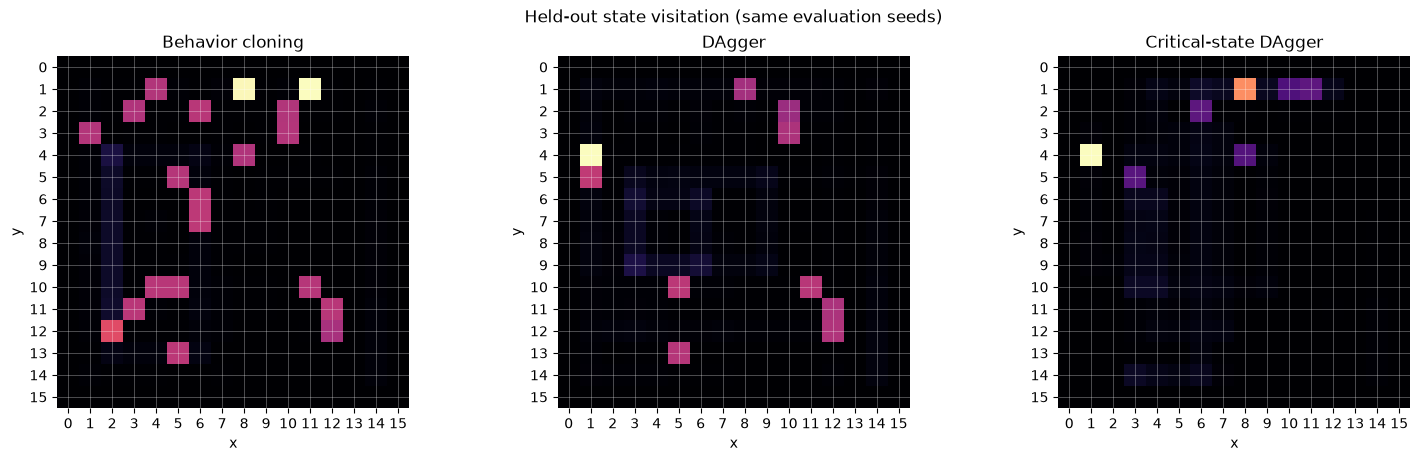

Saved comparison heatmaps to outputs\minigrid_imitation_learning\final_visit_heatmaps.png


In [16]:
# This is a helper function to plot success rate versus expert-label count. You may use it later. No need to change it.
def plot_label_efficiency(curves):
    plt.figure(figsize=(6.5, 4))
    for name, history, marker in curves:
        labels = [row["labels"] for row in history]
        success = [100.0 * row["success_rate"] for row in history]
        plt.plot(labels, success, marker=marker, linewidth=2, label=name)
    plt.xlabel("expert labels used")
    plt.ylabel("success rate (%)")
    plt.title("Label efficiency")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


# This is a helper function to display a compact Markdown results table. You may use it later. No need to change it.
def display_results_table(rows):
    lines = [
        "| method | expert labels used | success rate | average return | average episode length |",
        "|---|---:|---:|---:|---:|",
    ]
    for row in rows:
        lines.append(
            f"| {row['method']} | {row['labels']} | "
            f"{row['success_rate'] * 100:.1f}% | "
            f"{row['avg_return']:.3f} | "
            f"{row['avg_length']:.1f} |"
        )
    display(Markdown("\n".join(lines)))


# Re-evaluate every selected model on exactly the same held-out seeds.
comparison_specs = [
    ("Behavior cloning", bc_model, len(expert_data["actions"])),
    ("DAgger", dagger_model, dagger_label_count),
    ("Critical-state DAgger", critical_model, critical_label_count),
]
comparison_rows, comparison_evals = [], {}
for method, model, label_count in comparison_specs:
    metrics = evaluate_policy(
        lambda obs, env, current_model=model: model_action(current_model, obs),
        n_episodes=EVAL_EPISODES,
        seed_start=9000,
        record_positions=True,
    )
    comparison_evals[method] = metrics
    comparison_rows.append({"method": method, "labels": label_count, **metrics})

display_results_table(comparison_rows)
plot_label_efficiency([
    ("DAgger", dagger_history, "o"),
    ("Critical-state DAgger", critical_history, "s"),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, (method, _, _) in zip(axes, comparison_specs):
    plot_visit_heatmap(
        comparison_evals[method]["positions"],
        ax=ax,
        title=method,
        cmap="magma",
        show_colorbar=False,
    )
fig.suptitle("Held-out state visitation (same evaluation seeds)")
heatmap_path = OUTPUT_DIR / "final_visit_heatmaps.png"
fig.savefig(heatmap_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved comparison heatmaps to", heatmap_path)

## Reflection

The experiment shows the basic imitation-learning pattern. BC is simple and often learns useful behavior from expert trajectories, but it can suffer from distribution shift when its own early mistakes create unfamiliar states. DAgger reduces that mismatch by adding expert labels for learner-visited states. Critical-state DAgger keeps the same idea but tries to spend expert labels where the current policy is most uncertain, trading exhaustive labeling for a smaller, more focused query budget.
